# Optimasi Portofolio Saham LQ45 dengan Local Search
Demo singkat: memilih **5 saham LQ45** dengan Sharpe ratio tertinggi memakai **Hill Climbing, Simulated Annealing, dan Genetic Algorithm**, lalu dicocokkan dengan **brute force** (kunci jawaban).

> Hasil ini untuk keperluan kuliah, **bukan rekomendasi investasi**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
from src.masalah import PortfolioProblem, baca_daftar_saham
from src.algoritma import ALGORITMA, brute_force

## 1. Data dan fungsi objektif
Return dan risiko tiap saham dihitung dari data latih (Feb 2023 – Jan 2025).

In [2]:
p = PortfolioProblem()
info = baca_daftar_saham()
tabel = pd.DataFrame({'sektor': info.loc[p.tickers, 'sektor'].values,
                      'return/tahun': p.mu.round(3),
                      'volatilitas': np.sqrt(np.diag(p.cov)).round(3)}, index=p.tickers)
print('Jumlah saham:', p.n)
tabel.sort_values('return/tahun', ascending=False).head(8)

Jumlah saham: 42


,sektor,return/tahun,volatilitas
MAPA,Consumer Cyclicals,0.613,0.443
BRIS,Financials,0.501,0.398
ACES,Consumer Cyclicals,0.378,0.414
ADRO,Energy,0.335,0.415
ISAT,Infrastructures,0.320,0.344
JPFA,Consumer Non-Cyclicals,0.319,0.346
BRPT,Basic Materials,0.254,0.631
UNTR,Industrials,0.215,0.302


## 2. State dan tetangga
State = 5 saham. Tetangga = tukar 1 saham (185 tetangga).

In [3]:
rng = np.random.default_rng(0)
s = p.state_acak(rng)
print('State acak :', p.info(s)['saham'], ' Sharpe =', round(p.info(s)['sharpe'], 3))
print('Banyak tetangga:', len(p.semua_tetangga(s)))
t = p.tetangga_acak(s, rng)
print('Satu tetangga:', p.info(t)['saham'], ' Sharpe =', round(p.info(t)['sharpe'], 3))

State acak : ['BBTN', 'BMRI', 'ICBP', 'ISAT', 'MEDC']  Sharpe = 0.335
Banyak tetangga: 185
Satu tetangga: ['BBTN', 'BMRI', 'ICBP', 'ISAT', 'KLBF']  Sharpe = 0.095


## 3. Kunci jawaban: brute force

In [4]:
bf = brute_force(p)
print(f"{bf['jumlah']:,} kombinasi diperiksa dalam {bf['waktu']:.2f} detik")
print('Portofolio terbaik:', p.info(bf['state']))

850,668 kombinasi diperiksa dalam 0.50 detik
Portofolio terbaik: {'saham': ['ACES', 'ADRO', 'BRIS', 'JPFA', 'MAPA'], 'return': np.float64(0.42915275250033247), 'volatilitas': np.float64(0.20431653582646597), 'sharpe': np.float64(1.819004766290633)}


## 4. Tiga algoritma dengan jatah 500 evaluasi

In [5]:
baris = []
for nama, f in ALGORITMA.items():
    for seed in range(5):
        r = f(p, 500, np.random.default_rng(seed))
        baris.append({'algoritma': nama, 'seed': seed, 'sharpe': round(r['sharpe'], 4),
                      'ketemu terbaik?': abs(r['sharpe'] - bf['sharpe']) < 1e-9,
                      'saham': ' '.join(p.info(r['state'])['saham'])})
pd.DataFrame(baris)

,algoritma,seed,sharpe,ketemu terbaik?,saham
0,Hill Climbing,0,1.6467,False,ADRO BMRI BRIS ISAT MAPA
1,Hill Climbing,1,1.0946,False,ADRO BRIS MAPA MAPI TLKM
2,Hill Climbing,2,1.4271,False,AMRT BMRI BRIS JPFA MAPA
3,Hill Climbing,3,1.3512,False,ADRO ASII BBNI BRIS MAPA
4,Hill Climbing,4,1.3205,False,ADRO BRIS JSMR MAPA SIDO
5,Simulated Annealing,0,1.8190,True,ACES ADRO BRIS JPFA MAPA
6,Simulated Annealing,1,1.8190,True,ACES ADRO BRIS JPFA MAPA
7,Simulated Annealing,2,1.8190,True,ACES ADRO BRIS JPFA MAPA
8,Simulated Annealing,3,1.8190,True,ACES ADRO BRIS JPFA MAPA
9,Simulated Annealing,4,1.8190,True,ACES ADRO BRIS JPFA MAPA


## 5. Hasil eksperimen lengkap (30 run per algoritma)
Dibaca dari `results/` (hasil `python -m src.eksperimen`).

In [6]:
pd.read_csv('../results/ringkasan.csv')

,budget,algoritma,berhasil_persen,sharpe_rata2,sharpe_terburuk,waktu_ms
0,300,Genetic Algorithm,30.0000,1.7342,1.4886,16.5701
1,300,Hill Climbing,0.0000,1.1984,0.7641,3.0738
2,300,Simulated Annealing,66.6667,1.8033,1.7087,9.5599
3,500,Genetic Algorithm,43.3333,1.7588,1.4991,26.4933
4,500,Hill Climbing,3.3333,1.5120,1.0946,4.9353
5,500,Simulated Annealing,83.3333,1.8115,1.7433,18.1286
6,1000,Genetic Algorithm,70.0000,1.8016,1.7038,48.7051
7,1000,Hill Climbing,100.0000,1.8190,1.8190,12.2511
8,1000,Simulated Annealing,100.0000,1.8190,1.8190,35.0741
9,2000,Genetic Algorithm,96.6667,1.8165,1.7433,97.9200


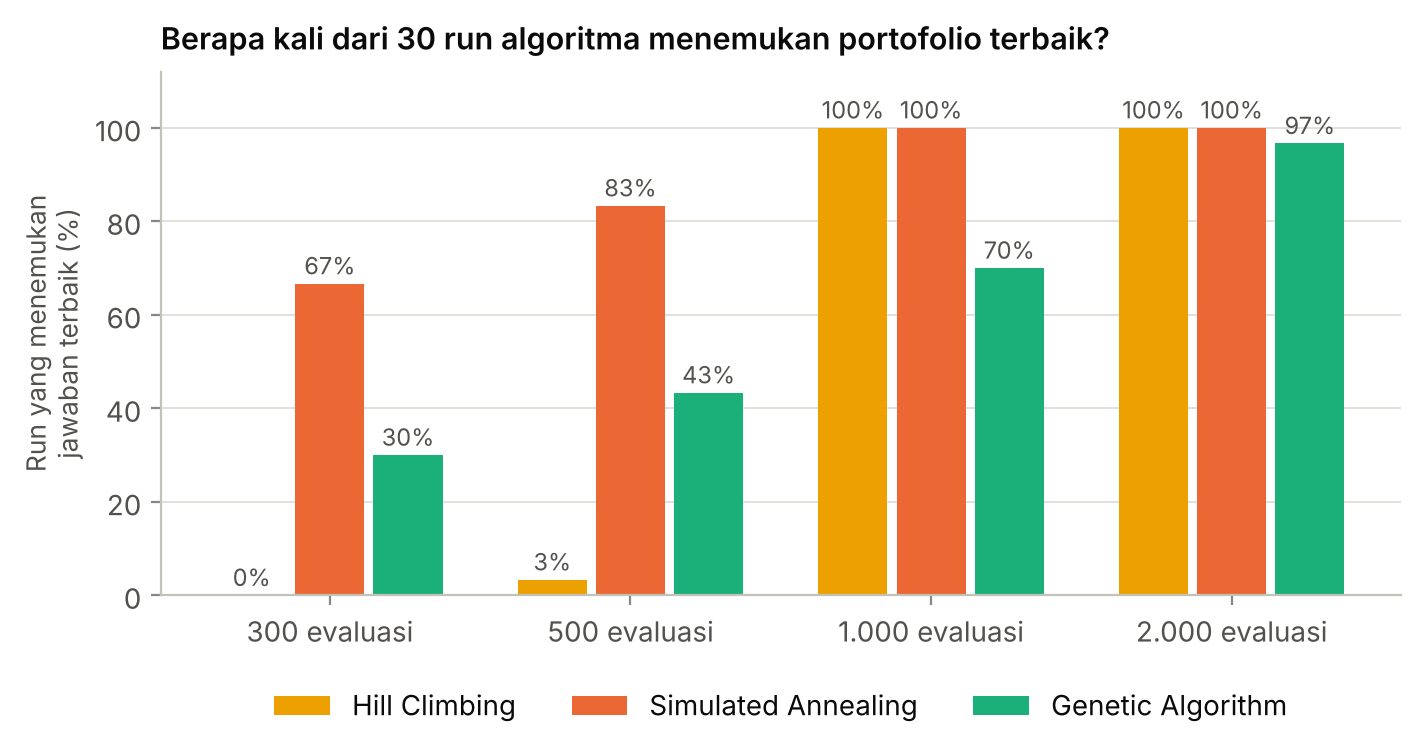

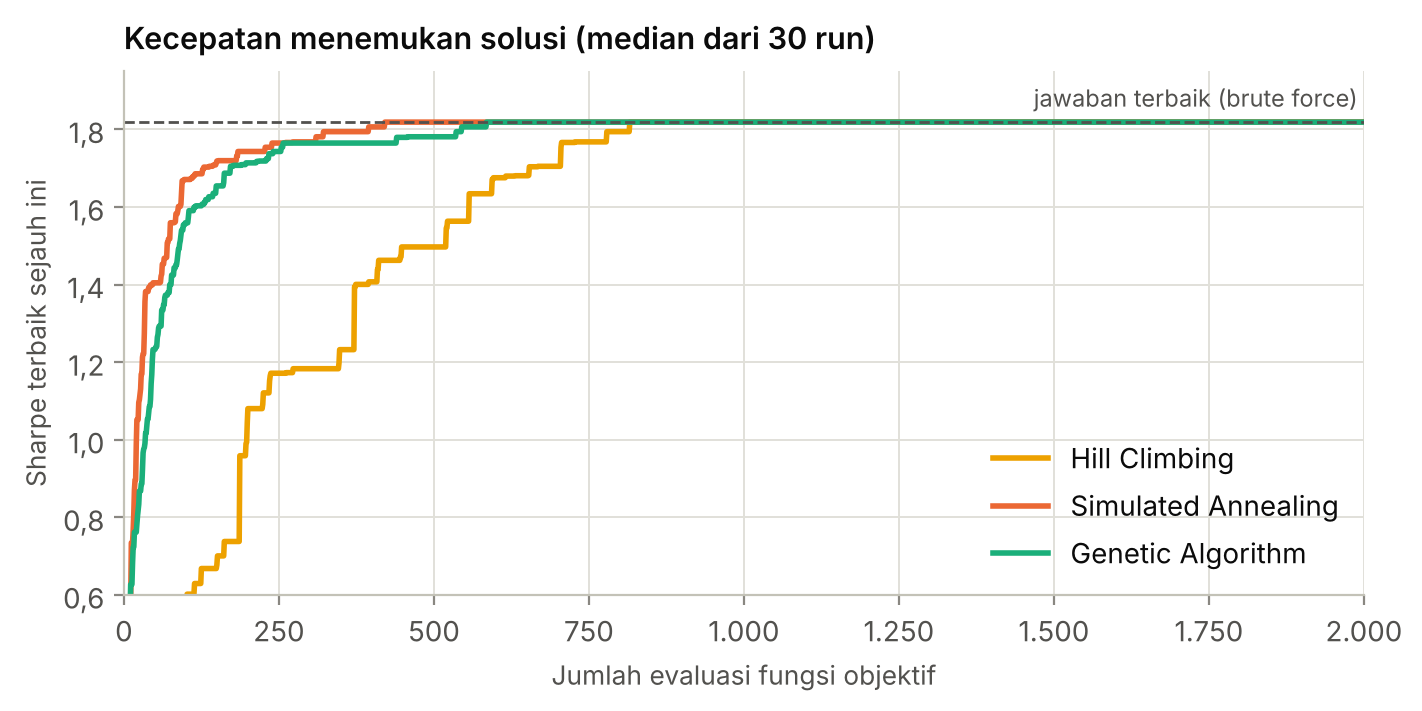

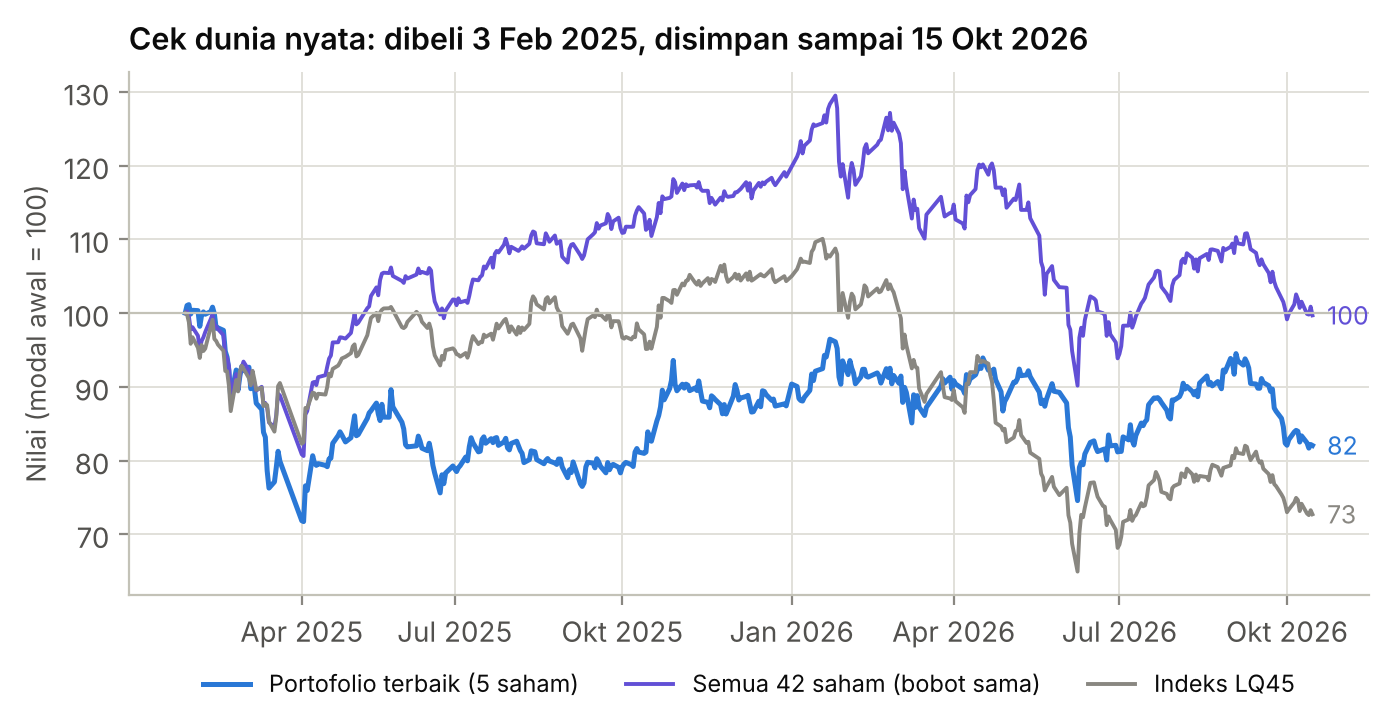

In [7]:
from IPython.display import Image, display
for g in ['g3_keberhasilan', 'g4_konvergensi', 'g5_uji_dunia_nyata']:
    display(Image(f'../results/grafik/{g}.png', width=760))